# Fine-tuning com LoRA: classificador de sentimento em português

**Modelo base:** BERTimbau (`neuralmind/bert-base-portuguese-cased`)  
**Técnica:** LoRA (via `peft`)  
**Tarefa:** classificar avaliações em negativo / neutro / positivo

Antes de rodar: no Colab cofigure o ambiente de execução para GPU T4**.

In [44]:
!pip -q install -U transformers datasets peft evaluate scikit-learn accelerate matplotlib

In [45]:
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from datasets import load_dataset, Dataset, DatasetDict
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, TrainingArguments, Trainer)
from peft import LoraConfig, TaskType, get_peft_model

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
print("GPU disponível:", torch.cuda.is_available())

GPU disponível: True


## 3. Carregar e preparar o dataset



Regra dos rótulos: nota 1-2 = negativo, 3 = neutro, 4-5 = positivo.

In [46]:
DATASET = "ruanchaves/b2w-reviews01"
COL_TEXTO, COL_NOTA = "review_text", "overall_rating"


try:
    raw = load_dataset(DATASET, split="train", revision="refs/convert/parquet")
    print("Carregado via Parquet")
except Exception as e1:
    print("Parquet falhou:", repr(e1)[:200])
    try:
        raw = load_dataset(DATASET, split="train", trust_remote_code=True)
        print("Carregado via script")
    except Exception as e2:
        raise RuntimeError(
            "Não consegui carregar o dataset. Rode numa célula: "
            '!pip install -q "datasets<4.0.0"  e depois reinicie o ambiente '
            "(Ambiente de execução > Reiniciar sessão) e rode tudo de novo."
        ) from e2
df = raw.to_pandas()[[COL_TEXTO, COL_NOTA]].dropna()
df = df[df[COL_TEXTO].str.len() > 10]

def nota_para_rotulo(n):
    n = int(n)
    return 0 if n <= 2 else (1 if n == 3 else 2)

df["label"] = df[COL_NOTA].apply(nota_para_rotulo)
df = df.rename(columns={COL_TEXTO: "text"})[["text", "label"]]
print(df["label"].value_counts())

Carregado via Parquet
label
2    79316
0    33772
1    16010
Name: count, dtype: int64


In [47]:
N_POR_CLASSE = 4000
partes = []
for lab in sorted(df["label"].unique()):
    sub = df[df["label"] == lab]
    partes.append(sub.sample(min(len(sub), N_POR_CLASSE), random_state=SEED))
df_bal = pd.concat(partes).reset_index(drop=True)

train_df, temp_df = train_test_split(df_bal, test_size=0.2, stratify=df_bal["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df["label"], random_state=SEED)
print(len(train_df), len(val_df), len(test_df))

ID2LABEL = {0: "negativo", 1: "neutro", 2: "positivo"}
LABEL2ID = {v: k for k, v in ID2LABEL.items()}

9600 1200 1200


## 4. Baseline: TF-IDF + Regressão Logística



In [48]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000)
X_train = tfidf.fit_transform(train_df["text"])
X_test = tfidf.transform(test_df["text"])

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, train_df["label"])
pred_base = lr.predict(X_test)

print("BASELINE")
print("Acurácia:", round(accuracy_score(test_df["label"], pred_base), 4))
print("F1 macro:", round(f1_score(test_df["label"], pred_base, average="macro"), 4))
print(classification_report(test_df["label"], pred_base, target_names=list(ID2LABEL.values())))

BASELINE
Acurácia: 0.715
F1 macro: 0.7109
              precision    recall  f1-score   support

    negativo       0.76      0.83      0.79       400
      neutro       0.62      0.55      0.58       400
    positivo       0.76      0.77      0.76       400

    accuracy                           0.71      1200
   macro avg       0.71      0.71      0.71      1200
weighted avg       0.71      0.71      0.71      1200



## 5. Tokenização

In [49]:
MODEL_NAME = "neuralmind/bert-base-portuguese-cased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenizar(batch):
    return tokenizer(batch["text"], truncation=True, max_length=128)

ds = DatasetDict({
    "train": Dataset.from_pandas(train_df.reset_index(drop=True)),
    "validation": Dataset.from_pandas(val_df.reset_index(drop=True)),
    "test": Dataset.from_pandas(test_df.reset_index(drop=True)),
})
ds_tok = ds.map(tokenizar, batched=True)
collator = DataCollatorWithPadding(tokenizer=tokenizer)

Map:   0%|          | 0/9600 [00:00<?, ? examples/s]

Map:   0%|          | 0/1200 [00:00<?, ? examples/s]

Map:   0%|          | 0/1200 [00:00<?, ? examples/s]

## 6. Configurar o LoRA



In [50]:
!pip install -q -U torchao

In [51]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=3, id2label=ID2LABEL, label2id=LABEL2ID
)

lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=8,
    lora_alpha=16,
    lora_dropout=0.1,
    target_modules=["query", "value"],
)
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

trainable params: 297,219 || all params: 109,222,662 || trainable%: 0.2721


## 7. Treinar

In [52]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1_macro": f1_score(labels, preds, average="macro"),
    }

args = TrainingArguments(
    output_dir="bertimbau-lora-sentimento",
    learning_rate=2e-4,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    num_train_epochs=3,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    logging_steps=50,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=ds_tok["train"],
    eval_dataset=ds_tok["validation"],
    data_collator=collator,
    compute_metrics=compute_metrics,
)
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.609514,0.596588,0.737500,0.729814
2,0.561553,0.582301,0.752500,0.747937
3,0.539390,0.571358,0.755833,0.755612


TrainOutput(global_step=900, training_loss=0.6282840792338054, metrics={'train_runtime': 243.5215, 'train_samples_per_second': 118.265, 'train_steps_per_second': 3.696, 'total_flos': 1750248001088640.0, 'train_loss': 0.6282840792338054, 'epoch': 3.0})

## 8. Avaliar no conjunto de teste e comparar com o baseline

LoRA (BERTimbau)
Acurácia: 0.7483
F1 macro: 0.7441
              precision    recall  f1-score   support

    negativo       0.82      0.86      0.84       400
      neutro       0.65      0.57      0.61       400
    positivo       0.75      0.82      0.79       400

    accuracy                           0.75      1200
   macro avg       0.74      0.75      0.74      1200
weighted avg       0.74      0.75      0.74      1200



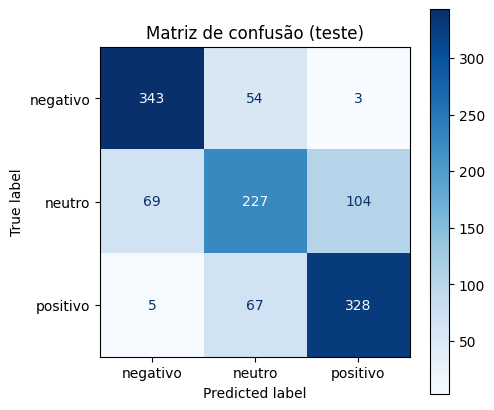

In [53]:
out = trainer.predict(ds_tok["test"])
pred_lora = np.argmax(out.predictions, axis=-1)
y_true = test_df["label"].values

print("LoRA (BERTimbau)")
print("Acurácia:", round(accuracy_score(y_true, pred_lora), 4))
print("F1 macro:", round(f1_score(y_true, pred_lora, average="macro"), 4))
print(classification_report(y_true, pred_lora, target_names=list(ID2LABEL.values())))

fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(
    y_true, pred_lora, display_labels=list(ID2LABEL.values()), ax=ax, cmap="Blues")
plt.title("Matriz de confusão (teste)")
plt.savefig("matriz_confusao.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Análise de erros

.

In [54]:
erros = test_df.reset_index(drop=True).copy()
erros["previsto"] = pred_lora
erros = erros[erros["label"] != erros["previsto"]]
erros["real"] = erros["label"].map(ID2LABEL)
erros["previsto"] = erros["previsto"].map(ID2LABEL)

pd.set_option("display.max_colwidth", 200)
erros[["text", "real", "previsto"]].sample(10, random_state=SEED)

,text,real,previsto
749,"Não tenho o que reclamar do produto. Muito bom. Porém se forem comprar... comprem em outro site. A Americana estourou com o prazo de dias úteis para a entrega, e nem ao menos entraram em contato...",negativo,neutro
961,"O faqueiro achei fraco, eles amassavam com facilidade. Porém o restante dos produtos em ótima qualidade.",positivo,neutro
472,É ótimo negócio pra quem sabe recarregar cartuchos... Usem tintas boas pq senão entope o cabeçote! Ah ela só imprime frente e verso se comprar a peça que encaixa atrás dela.,positivo,neutro
1024,Produto de muito bom na categoria de intermesiario.,neutro,positivo
251,"Super gostei o cafe sai quentinho e cremoso , facil de manusea la adorei!!!!",neutro,positivo
35,A mochila é bem espaçosa e bonita. Meu filho gostou bastante.,neutro,positivo
501,"Ótimo produto, bivolt, 2 baterias, luz de led, forte, maleta para guardar. Não deixa nada a desejar para Bosch ou Makita",neutro,positivo
946,Entrega rápida e produto de boa qualidade. Desenho bonito dos talheres.,positivo,neutro
1086,Gostei muito do produto e o recomendo aos interessados em pedalar,neutro,positivo
128,eu comprei no final de novembro e chegou no inicio de dezembro e no começo de fevereiro ambos os mouses que eu havia comprado haviam parado de funcionar mas o tempo que durou foi bem pouco mas for...,neutro,positivo


## 10. Publicar no Hugging Face



In [55]:
from huggingface_hub import notebook_login
notebook_login()

In [56]:
REPO = "btriz/bertimbau-lora-sentimento-ptbr"
trainer.model.push_to_hub(REPO)
tokenizer.push_to_hub(REPO)

README.md:   0%|          | 0.00/3.18k [00:00<?, ?B/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...adapter_model.safetensors:  47%|####6     |  559kB / 1.20MB            

Validating                    :           |   0%            

README.md:   0%|          | 0.00/3.16k [00:00<?, ?B/s]

No files have been modified since last commit. Skipping to prevent empty commit.


CommitInfo(commit_url='https://huggingface.co/btriz/bertimbau-lora-sentimento-ptbr/commit/422c2ca7d32934c7a9e9ca4a9f47afbf6f7455d4', commit_message='Upload tokenizer', commit_description='', oid='422c2ca7d32934c7a9e9ca4a9f47afbf6f7455d4', pr_url=None, repo_url=RepoUrl('https://huggingface.co/btriz/bertimbau-lora-sentimento-ptbr', endpoint='https://huggingface.co', repo_type='model', repo_id='btriz/bertimbau-lora-sentimento-ptbr'), pr_revision=None, pr_num=None)

## 11. Testar o modelo publicado

In [57]:
from peft import PeftModel

base = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=3, id2label=ID2LABEL, label2id=LABEL2ID
)
modelo = PeftModel.from_pretrained(base, REPO)
modelo = modelo.to("cuda" if torch.cuda.is_available() else "cpu")
tok = AutoTokenizer.from_pretrained(REPO)
modelo.eval()

def prever(texto):
    entrada = tok(texto, return_tensors="pt", truncation=True, max_length=128).to(modelo.device)
    with torch.no_grad():
        probs = torch.softmax(modelo(**entrada).logits, dim=-1)[0]
    return {ID2LABEL[i]: round(float(p), 3) for i, p in enumerate(probs)}

print(prever("Chegou super rápido e o produto é ótimo, recomendo!"))
print(prever("Demorou demais e veio com defeito. Péssimo."))
print(prever("Produto ok, nada demais."))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

adapter_config.json:   0%|          | 0.00/1.14k [00:00<?, ?B/s]

adapter_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.20MB            

adapter_model.safetensors: downloading bytes:           |  0.00B            

tokenizer_config.json:   0%|          | 0.00/380 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/678k [00:00<?, ?B/s]

{'negativo': 0.002, 'neutro': 0.04, 'positivo': 0.958}
{'negativo': 0.899, 'neutro': 0.092, 'positivo': 0.008}
{'negativo': 0.039, 'neutro': 0.615, 'positivo': 0.346}
